In [30]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

In [2]:
data_folder = '../datasets/'

os.listdir(data_folder)

['SX5E.csv', 'EURUSD.csv', 'RUT.csv', 'GSPC.csv']

In [3]:
df = pd.read_csv(os.path.join(data_folder, 'RUT.csv'))

df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,1987-09-10,167.440002,168.979996,167.440002,168.970001,168.970001,179800000
1,1987-09-11,168.970001,170.539993,168.750000,170.539993,170.539993,178000000
2,1987-09-14,170.529999,170.949997,170.149994,170.429993,170.429993,154400000
3,1987-09-15,170.419998,170.440002,169.130005,169.199997,169.199997,136200000
4,1987-09-16,169.309998,170.029999,168.820007,168.919998,168.919998,195700000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8143 entries, 0 to 8142
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       8143 non-null   str    
 1   Open       8143 non-null   float64
 2   High       8143 non-null   float64
 3   Low        8143 non-null   float64
 4   Close      8143 non-null   float64
 5   Adj Close  8143 non-null   float64
 6   Volume     8143 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 445.4 KB


In [6]:
df.isna().sum()

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [25]:
df['T-1 Close'] = df['Close'].shift(1)
df2 = df[['Date', 'Close', 'T-1 Close']].copy()

In [26]:
df2 = df2.iloc[1 : ]
df2

,Date,Close,T-1 Close
1,1987-09-11,170.539993,168.970001
2,1987-09-14,170.429993,170.539993
3,1987-09-15,169.199997,170.429993
4,1987-09-16,168.919998,169.199997
5,1987-09-17,168.820007,168.919998
...,...,...,...
8138,2019-12-24,1678.010010,1674.140015
8139,2019-12-26,1677.670044,1678.010010
8140,2019-12-27,1669.030029,1677.670044
8141,2019-12-30,1664.150024,1669.030029


In [27]:
df2['Gross Return'] = df2['Close'] / df2['T-1 Close']
df2

,Date,Close,T-1 Close,Gross Return
1,1987-09-11,170.539993,168.970001,1.009292
2,1987-09-14,170.429993,170.539993,0.999355
3,1987-09-15,169.199997,170.429993,0.992783
4,1987-09-16,168.919998,169.199997,0.998345
5,1987-09-17,168.820007,168.919998,0.999408
...,...,...,...,...
8138,2019-12-24,1678.010010,1674.140015,1.002312
8139,2019-12-26,1677.670044,1678.010010,0.999797
8140,2019-12-27,1669.030029,1677.670044,0.994850
8141,2019-12-30,1664.150024,1669.030029,0.997076


In [28]:
df2['Net Return'] = (df2['Close'] - df2['T-1 Close']) / df['T-1 Close']
df2

,Date,Close,T-1 Close,Gross Return,Net Return
1,1987-09-11,170.539993,168.970001,1.009292,0.009292
2,1987-09-14,170.429993,170.539993,0.999355,-0.000645
3,1987-09-15,169.199997,170.429993,0.992783,-0.007217
4,1987-09-16,168.919998,169.199997,0.998345,-0.001655
5,1987-09-17,168.820007,168.919998,0.999408,-0.000592
...,...,...,...,...,...
8138,2019-12-24,1678.010010,1674.140015,1.002312,0.002312
8139,2019-12-26,1677.670044,1678.010010,0.999797,-0.000203
8140,2019-12-27,1669.030029,1677.670044,0.994850,-0.005150
8141,2019-12-30,1664.150024,1669.030029,0.997076,-0.002924


In [24]:
df2['Net Return 2'] = df2['Gross Return'] - 1
df2

,Close,T-1 Close,Gross Return,Net Return,Net Return 2
1,170.539993,168.970001,1.009292,0.009292,0.009292
2,170.429993,170.539993,0.999355,-0.000645,-0.000645
3,169.199997,170.429993,0.992783,-0.007217,-0.007217
4,168.919998,169.199997,0.998345,-0.001655,-0.001655
5,168.820007,168.919998,0.999408,-0.000592,-0.000592
...,...,...,...,...,...
8138,1678.010010,1674.140015,1.002312,0.002312,0.002312
8139,1677.670044,1678.010010,0.999797,-0.000203,-0.000203
8140,1669.030029,1677.670044,0.994850,-0.005150,-0.005150
8141,1664.150024,1669.030029,0.997076,-0.002924,-0.002924


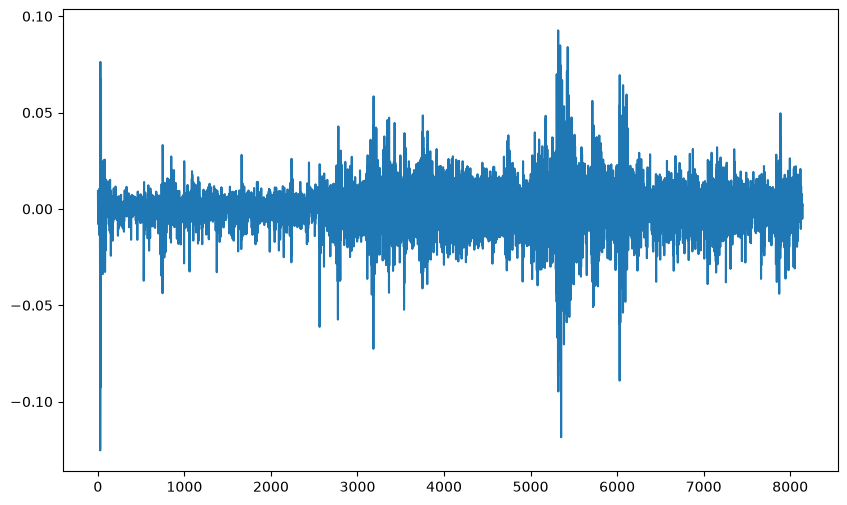

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(df2['Net Return'])
plt.show()

In [31]:
df2['Log Return'] = np.log(df2['Gross Return'])
df2

,Date,Close,T-1 Close,Gross Return,Net Return,Log Return
1,1987-09-11,170.539993,168.970001,1.009292,0.009292,0.009249
2,1987-09-14,170.429993,170.539993,0.999355,-0.000645,-0.000645
3,1987-09-15,169.199997,170.429993,0.992783,-0.007217,-0.007243
4,1987-09-16,168.919998,169.199997,0.998345,-0.001655,-0.001656
5,1987-09-17,168.820007,168.919998,0.999408,-0.000592,-0.000592
...,...,...,...,...,...,...
8138,2019-12-24,1678.010010,1674.140015,1.002312,0.002312,0.002309
8139,2019-12-26,1677.670044,1678.010010,0.999797,-0.000203,-0.000203
8140,2019-12-27,1669.030029,1677.670044,0.994850,-0.005150,-0.005163
8141,2019-12-30,1664.150024,1669.030029,0.997076,-0.002924,-0.002928


In [34]:
df2['Predict Close'] = np.exp(df2['Log Return']) * df2['T-1 Close']

df2

,Date,Close,T-1 Close,Gross Return,Net Return,Log Return,Predict Close
1,1987-09-11,170.539993,168.970001,1.009292,0.009292,0.009249,170.539993
2,1987-09-14,170.429993,170.539993,0.999355,-0.000645,-0.000645,170.429993
3,1987-09-15,169.199997,170.429993,0.992783,-0.007217,-0.007243,169.199997
4,1987-09-16,168.919998,169.199997,0.998345,-0.001655,-0.001656,168.919998
5,1987-09-17,168.820007,168.919998,0.999408,-0.000592,-0.000592,168.820007
...,...,...,...,...,...,...,...
8138,2019-12-24,1678.010010,1674.140015,1.002312,0.002312,0.002309,1678.010010
8139,2019-12-26,1677.670044,1678.010010,0.999797,-0.000203,-0.000203,1677.670044
8140,2019-12-27,1669.030029,1677.670044,0.994850,-0.005150,-0.005163,1669.030029
8141,2019-12-30,1664.150024,1669.030029,0.997076,-0.002924,-0.002928,1664.150024


In [36]:
compound_return = df2['Log Return'].sum()

In [37]:
compound_return

np.float64(2.2899411101360556)